# Final project: design and analyze an experiment

**Free delivery on orders over 100 SAR**

Experiments, A/B Testing & Causal Inference, SDAIA Academy. Presentation on 11 November 2026.

The users in this notebook are simulated with seed 2026. The hidden true effect is a check after the analysis. It is not an input to the decision.


## 0. Project details

| Item | Value |
|---|---|
| Project | Free delivery on orders over 100 SAR |
| Organization or product | Bayt Market, a grocery-delivery app. |


## 1. Question and hypothesis

- **Decision:** Should Bayt Market waive the delivery fee on paid orders of 100 SAR or more?
- **Hypothesis:** If we waive that fee, then the share of eligible users who place at least one paid order within 7 days will rise by at least 1 percentage point, because the fee is a reason people stop at checkout.
- **What would change our mind:** an order-rate interval entirely below zero, an interval that rules out a gain of 1 percentage point, or a significant drop in profit per user. An inconclusive order-rate result is not a reason to ship the waiver.


## 2. Design

| Item | Value |
|---|---|
| Unit of randomization | The user account. Each user enters once. |
| Allocation ratio | 50/50, fixed with SHA-256 of `free_delivery_100_v1:user_id`. |
| Primary metric | 7-day order rate: the share of randomized users with at least one paid order. |
| Secondary metrics | Revenue per randomized user. Average order value among buyers, which is descriptive because the offer can change who buys. |
| Guardrail metrics | Profit per user (a drop is bad). Order cancellation per user (a rise is bad). Contact with support per user (a rise is bad). |
| SUTVA | One user's waiver does not change another user's order. This fails if couriers run out of capacity, or if people in one household share an account. |

Group A keeps the current delivery fee. Group B gets the fee waived on paid orders of at least 100 SAR. Prices, the catalog, and the rest of the app stay the same. The analysis keeps every randomized user, whether or not their basket crossed 100 SAR.


## Ready-made tools

Run the next cell as it stands. It holds the sample-size, duration, SRM, confidence-interval, and decision functions from the course.


In [1]:
import warnings
from hashlib import sha256

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats
from statsmodels.stats.multitest import multipletests

TEAL, ORANGE, NAVY, GRAY = "#1F6B45", "#E36A2C", "#143028", "#8A9186"
plt.rcParams.update({
    "figure.figsize": (9, 4.4),
    "figure.dpi": 120,
    "axes.edgecolor": "#5C6B62",
    "axes.labelcolor": NAVY,
    "text.color": NAVY,
    "axes.grid": True,
    "grid.color": "#E2E8E4",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 20)


def n_per_group_proportions(p_control, p_treatment, alpha=0.05, power=0.80):
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_power = stats.norm.ppf(power)
    variance = p_control * (1 - p_control) + p_treatment * (1 - p_treatment)
    return int(np.ceil((z_alpha + z_power) ** 2 * variance / (p_treatment - p_control) ** 2))


def mde_proportions(p_control, n_per_group, alpha=0.05, power=0.80):
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    z_power = stats.norm.ppf(power)
    return (z_alpha + z_power) * np.sqrt(2 * p_control * (1 - p_control) / n_per_group)


def duration_days(n_per_group, daily_new_users, groups=2, round_to_weeks=True):
    days = int(np.ceil(n_per_group * groups / daily_new_users))
    return int(np.ceil(days / 7) * 7) if round_to_weeks else days


def srm_check(n_a, n_b, expected_share_b=0.5, threshold=0.001):
    total = n_a + n_b
    chi2, p_value = stats.chisquare(
        [n_a, n_b],
        f_exp=[total * (1 - expected_share_b), total * expected_share_b],
    )
    verdict = "Problem in the allocation (SRM). Do not trust the results." if p_value < threshold else "Allocation is healthy."
    print(f"A={n_a:,}  B={n_b:,}  chi-square={chi2:.2f}  p={p_value:.3g}  {verdict}")
    return p_value


def diff_ci(group_a, group_b, alpha=0.05):
    """Difference of means, B minus A, with a normal 95% interval."""
    group_a = np.asarray(group_a, dtype=float)
    group_b = np.asarray(group_b, dtype=float)
    difference = group_b.mean() - group_a.mean()
    standard_error = np.sqrt(group_a.var(ddof=1) / len(group_a) + group_b.var(ddof=1) / len(group_b))
    z_critical = stats.norm.ppf(1 - alpha / 2)
    return {
        "diff": difference,
        "ci_low": difference - z_critical * standard_error,
        "ci_high": difference + z_critical * standard_error,
        "se": standard_error,
        "p": 2 * stats.norm.sf(abs(difference / standard_error)),
    }


def decide(ci_low, ci_high, mde, guardrails_ok=True):
    if ci_high < 0:
        return "Do not launch. The new version hurt the primary metric."
    if ci_low > 0 and not guardrails_ok:
        return "Do not launch yet. The primary metric improved, but a guardrail got worse. Fix the problem, then check again."
    if ci_low > 0:
        return "Launch. The effect is positive with confidence, and the guardrails are healthy."
    if ci_high < mde:
        return "Do not launch. We have ruled out an effect of the size we care about."
    return "No decision yet. Extend the experiment, or redesign it with more power."


print("Tools are ready.")


Tools are ready.


## 3. Sample size and duration

The design inputs below were set before any outcomes were generated. The baseline is 10% of eligible users ordering within 7 days. A gain of 1 percentage point is the smallest change that would justify a new delivery policy. Alpha is 5% and power is 80%, both two-sided. About 5,000 eligible users open the app on a typical day, and the offer is split evenly.


In [2]:
CONFIG = {
    "project": "Free delivery on orders over 100 SAR",
    "baseline_conversion": 0.10,
    "mde_abs": 0.010,
    "alpha": 0.05,
    "power": 0.80,
    "daily_new_users": 5_000,
    "treatment_share": 0.5,
    "true_lift_abs": 0.008,
    "order_value_mean": 120,
    "order_value_sd": 50,
    "order_value_effect": 0,
    "margin": 0.25,
    "extra_cost_per_order_b": 15,
    "free_delivery_threshold": 100,
    "cancel_rate": 0.05,
    "cancel_effect": 0,
    "support_rate": 0.03,
    "support_effect": 0,
    "activity_strength": 0.8,
    "novelty_boost": 0,
    "srm_bug_share": 0,
    "seed": 2026,
    "experiment_id": "free_delivery_100_v1",
}


In [3]:
settings = CONFIG
n_per_group = n_per_group_proportions(
    settings["baseline_conversion"],
    settings["baseline_conversion"] + settings["mde_abs"],
    settings["alpha"],
    settings["power"],
)
minimum_days = duration_days(n_per_group, settings["daily_new_users"], round_to_weeks=False)
days = duration_days(n_per_group, settings["daily_new_users"])
planned_total = days * settings["daily_new_users"]
planned_per_group = planned_total // 2
one_week_per_group = 7 * settings["daily_new_users"] // 2
mde_planned = mde_proportions(
    settings["baseline_conversion"], planned_per_group, settings["alpha"], settings["power"]
)
mde_one_week = mde_proportions(
    settings["baseline_conversion"], one_week_per_group, settings["alpha"], settings["power"]
)

print(f"Users per group for a {settings['mde_abs'] * 100:.2f} point effect: {n_per_group:,}")
print(f"Total users at that size: {2 * n_per_group:,}")
print(f"Enrollment days before rounding: {minimum_days}")
print(f"Enrollment days after rounding up to full weeks: {days}")
print(f"Expected users in that window: {planned_total:,} ({planned_per_group:,} per group)")
print(f"Smallest detectable effect over the planned window: {mde_planned * 100:.2f} percentage points")
print(f"Smallest detectable effect if enrollment is capped at one week: {mde_one_week * 100:.2f} percentage points")

if mde_planned <= settings["mde_abs"]:
    duration_text = (
        f"The duration is acceptable. We need {n_per_group:,} users per group. "
        f"At {settings['daily_new_users']:,} eligible users a day that is {minimum_days} days, "
        f"which rounds up to {days} days. The planned week can detect about {mde_planned * 100:.2f} "
        f"percentage points, which is tighter than the {settings['mde_abs'] * 100:.2f} point effect we care about. "
        "We will not shorten the test. Each user still needs a full 7-day outcome window, "
        "so the single readout is 14 days after the first user enters."
    )
else:
    duration_text = (
        f"The duration is not acceptable. Over {days} days the detectable effect is "
        f"{mde_planned * 100:.2f} percentage points, larger than the {settings['mde_abs'] * 100:.2f} "
        "point effect we care about. We would raise daily traffic or accept a larger effect before launching the test."
    )
display(Markdown(duration_text))


Users per group for a 1.00 point effect: 14,749
Total users at that size: 29,498
Enrollment days before rounding: 6
Enrollment days after rounding up to full weeks: 7
Expected users in that window: 35,000 (17,500 per group)
Smallest detectable effect over the planned window: 0.90 percentage points
Smallest detectable effect if enrollment is capped at one week: 0.90 percentage points


The duration is acceptable. We need 14,749 users per group. At 5,000 eligible users a day that is 6 days, which rounds up to 7 days. The planned week can detect about 0.90 percentage points, which is tighter than the 1.00 point effect we care about. We will not shorten the test. Each user still needs a full 7-day outcome window, so the single readout is 14 days after the first user enters.

## 4. Analysis plan

This plan is fixed before the simulated outcomes are generated. Any change after seeing results would be listed in the report. None was made.

1. **Sample ratio mismatch.** Compare the group sizes with a chi-square test against a 50/50 split. If p < 0.001, stop. Do not interpret the effect until the allocation bug is found.
2. **Primary metric.** Estimate the order rate in B minus the order rate in A for every randomized user. Report a two-sided 95% interval with the normal approximation. CUPED, using orders in the 90 days before entry, is a precision check. The decision uses the unadjusted interval.
3. **Secondary metrics.** Compare revenue per randomized user, and average order value among buyers. Adjust the two p-values with Benjamini-Hochberg at 5%. The buyer-only average is descriptive.
4. **Guardrail metrics.** A guardrail shows significant deterioration when its 95% interval lies entirely in the bad direction: the upper bound is below zero for profit, or the lower bound is above zero for cancellation and for support. Otherwise the guardrail is healthy.
5. **When we analyze.** One readout, after 7 enrollment days and a completed 7-day window for every user. No peeking. The plot of the effect by entry day is a check for a novelty spike. It is not a second decision.
6. **Decision rule.** Do not launch if any guardrail shows significant deterioration. If every guardrail is healthy, apply `decide` to the unadjusted order-rate interval and the 1 percentage point effect we set out to detect.


## 5. Simulated data

Each row is one eligible user. The variant comes from the hash in the design. In group A the order rate is centered on 10%, and it moves with a latent activity score. That same score drives orders in the prior 90 days, which gives CUPED a pre-experiment covariate. Group B adds a hidden lift of 0.8 percentage points. A paid order is worth about 120 SAR. Profit keeps 25% of revenue on orders that are not cancelled, then subtracts 15 SAR when a group B order qualifies for the waiver (the basket is at least 100 SAR). Five percent of orders are cancelled. Three percent of users contact support. The novelty boost and the allocation bug are both zero. The seed is 2026.

The comparison with the hidden lift comes after the estimates. The decision does not use it.


In [4]:
def assigned_variant(user_id, experiment_id, treatment_share):
    digest = sha256(f"{experiment_id}:{user_id}".encode()).digest()
    bucket = int.from_bytes(digest[:8], "big") / 2**64
    return "B" if bucket < treatment_share else "A"


def simulate_experiment(cfg, enrollment_days):
    """One row per user for a completed enrollment window."""
    random = np.random.default_rng(cfg["seed"])
    n_users = enrollment_days * cfg["daily_new_users"]
    user_ids = [f"user-{index:06d}" for index in range(1, n_users + 1)]
    entry_day = np.repeat(np.arange(1, enrollment_days + 1), cfg["daily_new_users"])
    variant = np.array([
        assigned_variant(user_id, cfg["experiment_id"], cfg["treatment_share"])
        for user_id in user_ids
    ])
    if cfg["srm_bug_share"] > 0:
        control_index = np.flatnonzero(variant == "A")
        n_flip = int(cfg["srm_bug_share"] * len(control_index))
        variant[control_index[:n_flip]] = "B"

    treated = (variant == "B").astype(int)
    activity = random.normal(0, 1, n_users)
    baseline = cfg["baseline_conversion"]
    logit = np.log(baseline / (1 - baseline)) + cfg["activity_strength"] * activity
    p_control = 1 / (1 + np.exp(-logit))
    p_control = np.clip(p_control * baseline / p_control.mean(), 0, 1)
    pre_orders = random.poisson(5 * p_control / baseline)
    lift = cfg["true_lift_abs"] * (1 + cfg["novelty_boost"] * np.exp(-(entry_day - 1) / 3))
    p_order = np.clip(p_control + lift * treated, 0, 1)
    ordered = random.binomial(1, p_order)
    order_value = np.maximum(
        10,
        random.normal(
            cfg["order_value_mean"] + cfg["order_value_effect"] * treated,
            cfg["order_value_sd"],
            n_users,
        ),
    )
    revenue = ordered * order_value
    cancel_probability = np.clip(cfg["cancel_rate"] + cfg["cancel_effect"] * treated, 0, 1)
    cancelled = ordered * random.binomial(1, cancel_probability)
    support_probability = np.clip(cfg["support_rate"] + cfg["support_effect"] * treated, 0, 1)
    contacted_support = random.binomial(1, support_probability)
    qualifies_for_waiver = (
        (ordered == 1) & (treated == 1) & (order_value >= cfg["free_delivery_threshold"])
    )
    profit = (
        revenue * cfg["margin"] * (1 - cancelled)
        - qualifies_for_waiver * cfg["extra_cost_per_order_b"]
    )
    experiment = pd.DataFrame({
        "user_id": user_ids,
        "day": entry_day,
        "variant": variant,
        "pre_orders_90d": pre_orders,
        "ordered": ordered,
        "order_value": np.where(ordered == 1, order_value, np.nan),
        "revenue": revenue,
        "cancelled": cancelled,
        "contacted_support": contacted_support,
        "profit": profit,
    })
    return experiment


data = simulate_experiment(CONFIG, days)
print(f"Simulated {len(data):,} users over {days} enrollment days. Seed {CONFIG['seed']}.")
print(data.groupby("variant").size().rename("users").to_frame())


Simulated 35,000 users over 7 enrollment days. Seed 2026.
         users
variant       
A        17593
B        17407


## 6. Trust checks

The SRM check compares the realized split with the planned 50/50 allocation. A p-value below 0.001 means the assignment is broken and the effect estimates should not be used.


In [5]:
counts = data["variant"].value_counts()
srm_p = srm_check(
    int(counts["A"]),
    int(counts["B"]),
    CONFIG["treatment_share"],
    threshold=0.001,
)
if srm_p < 0.001:
    raise RuntimeError("SRM failed. Stop before estimating effects.")
if data["user_id"].duplicated().any():
    raise RuntimeError("A user appears more than once.")
print("One row per user, and the allocation check passed.")


A=17,593  B=17,407  chi-square=0.99  p=0.32  Allocation is healthy.
One row per user, and the allocation check passed.


## 7. Analysis

### 7.1 Primary metric, with CUPED


In [6]:
group_a = data.loc[data["variant"].eq("A")]
group_b = data.loc[data["variant"].eq("B")]
primary = diff_ci(group_a["ordered"], group_b["ordered"], CONFIG["alpha"])

pre_orders = data["pre_orders_90d"]
pre_variance = pre_orders.var(ddof=1)
theta = np.cov(data["ordered"], pre_orders)[0, 1] / pre_variance if pre_variance > 0 else 0.0
adjusted = data["ordered"] - theta * (pre_orders - pre_orders.mean())
primary_cuped = diff_ci(adjusted.loc[group_a.index], adjusted.loc[group_b.index], CONFIG["alpha"])
variance_reduction = 1 - (primary_cuped["se"] / primary["se"]) ** 2

primary_table = pd.DataFrame(
    [primary, primary_cuped],
    index=["Unadjusted", "CUPED"],
)
primary_table[["diff", "ci_low", "ci_high", "se"]] *= 100
primary_table = primary_table.rename(columns={
    "diff": "Difference (pp)",
    "ci_low": "95% low",
    "ci_high": "95% high",
    "se": "SE (pp)",
    "p": "p",
})
print(
    f"Order rate: A {group_a['ordered'].mean():.2%} ({int(group_a['ordered'].sum()):,} of {len(group_a):,}), "
    f"B {group_b['ordered'].mean():.2%} ({int(group_b['ordered'].sum()):,} of {len(group_b):,})."
)
print(f"CUPED reduced the variance of the effect estimate by {variance_reduction:.1%}.")
display(primary_table.round(4))


Order rate: A 10.14% (1,784 of 17,593), B 10.58% (1,842 of 17,407).
CUPED reduced the variance of the effect estimate by 3.6%.


,Difference (pp),95% low,95% high,SE (pp),p
Unadjusted,0.4416,-0.197,1.0801,0.3258,0.1754
CUPED,0.4290,-0.198,1.0559,0.3199,0.1799


### 7.2 Secondary metrics, with a multiple-testing correction


In [7]:
secondary_results = {
    "Revenue per user (SAR)": diff_ci(group_a["revenue"], group_b["revenue"], CONFIG["alpha"]),
    "Order value among buyers (SAR)": diff_ci(
        group_a["order_value"].dropna(), group_b["order_value"].dropna(), CONFIG["alpha"]
    ),
}
secondary = pd.DataFrame(secondary_results).T
rejected, adjusted_p, _, _ = multipletests(secondary["p"], alpha=CONFIG["alpha"], method="fdr_bh")
secondary["p after BH"] = adjusted_p
secondary["Significant after BH"] = rejected
secondary["A"] = [group_a["revenue"].mean(), group_a["order_value"].mean()]
secondary["B"] = [group_b["revenue"].mean(), group_b["order_value"].mean()]
secondary_view = secondary[
    ["A", "B", "diff", "ci_low", "ci_high", "p", "p after BH", "Significant after BH"]
].rename(columns={"diff": "Difference", "ci_low": "95% low", "ci_high": "95% high"})
display(secondary_view.round(4))
print("Benjamini-Hochberg is applied to the two secondary p-values. The buyer-only comparison is descriptive.")


,A,B,Difference,95% low,95% high,p,p after BH,Significant after BH
Revenue per user (SAR),12.2402,12.5776,0.3373,-0.4939,1.1685,0.4264,0.4264,False
Order value among buyers (SAR),120.7077,118.8586,-1.8491,-4.9908,1.2925,0.2487,0.4264,False


Benjamini-Hochberg is applied to the two secondary p-values. The buyer-only comparison is descriptive.


### 7.3 Guardrail metrics


In [8]:
guardrail_specs = [
    ("profit", "Profit per user", "down", 1, "SAR per user"),
    ("cancelled", "Cancellation per user", "up", 100, "percentage points"),
    ("contacted_support", "Support contact per user", "up", 100, "percentage points"),
]
guard_rows = []
guard_status = {}
for column, label, bad_direction, scale, unit in guardrail_specs:
    result = diff_ci(group_a[column], group_b[column], CONFIG["alpha"])
    if bad_direction == "down":
        deteriorated = result["ci_high"] < 0
    elif bad_direction == "up":
        deteriorated = result["ci_low"] > 0
    else:
        raise ValueError(f"Unknown guardrail direction: {bad_direction}")
    status = "Significant deterioration" if deteriorated else "Healthy"
    guard_status[label] = status
    guard_rows.append({
        "Metric": label,
        "A": group_a[column].mean() * scale,
        "B": group_b[column].mean() * scale,
        "Difference": result["diff"] * scale,
        "95% low": result["ci_low"] * scale,
        "95% high": result["ci_high"] * scale,
        "Unit": unit,
        "Status": status,
        "diff_raw": result["diff"],
        "ci_low_raw": result["ci_low"],
        "ci_high_raw": result["ci_high"],
    })

guard_table = pd.DataFrame(guard_rows).set_index("Metric")
display(guard_table[["A", "B", "Difference", "95% low", "95% high", "Unit", "Status"]].round(4))


,A,B,Difference,95% low,95% high,Unit,Status
Metric,,,,,,,
Profit per user,2.9071,1.9763,-0.9308,-1.1039,-0.7576,SAR per user,Significant deterioration
Cancellation per user,0.5173,0.4998,-0.0175,-0.1665,0.1316,percentage points,Healthy
Support contact per user,3.0580,3.1654,0.1074,-0.2565,0.4712,percentage points,Healthy


### 7.4 Novelty check

The plot shows the order-rate effect for users who entered on each day, against the overall effect. Daily samples are smaller, so the points are noisy. The decision uses the overall estimate from the analysis plan.


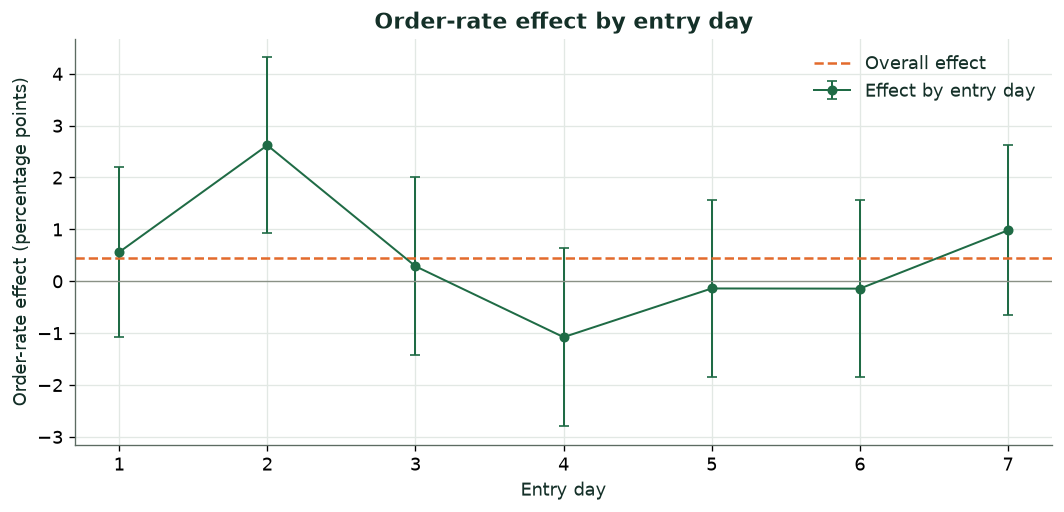

The hidden true lift is 0.80 percentage points. The unadjusted interval covers it. The decision does not use the hidden lift.
The by-day series is a check. The readout remains the single overall estimate.


In [9]:
daily_rows = []
for entry_day, cohort in data.groupby("day"):
    result = diff_ci(
        cohort.loc[cohort["variant"].eq("A"), "ordered"],
        cohort.loc[cohort["variant"].eq("B"), "ordered"],
        CONFIG["alpha"],
    )
    daily_rows.append({"day": int(entry_day), **result})
daily_effect = pd.DataFrame(daily_rows).set_index("day")

figure, axis = plt.subplots()
axis.errorbar(
    daily_effect.index,
    daily_effect["diff"] * 100,
    yerr=(daily_effect["ci_high"] - daily_effect["diff"]) * 100,
    fmt="o-",
    color=TEAL,
    markersize=5,
    linewidth=1.2,
    capsize=3,
    label="Effect by entry day",
)
axis.axhline(primary["diff"] * 100, color=ORANGE, linestyle="--", label="Overall effect")
axis.axhline(0, color=GRAY, linewidth=0.8)
axis.set_xlabel("Entry day")
axis.set_ylabel("Order-rate effect (percentage points)")
axis.set_title("Order-rate effect by entry day")
axis.set_xticks(list(daily_effect.index))
axis.legend(loc="best")
figure.tight_layout()
display(figure)
plt.close(figure)

hidden_lift = CONFIG["true_lift_abs"]
covers_truth = primary["ci_low"] <= hidden_lift <= primary["ci_high"]
coverage = "covers" if covers_truth else "does not cover"
print(
    f"The hidden true lift is {hidden_lift * 100:.2f} percentage points. "
    f"The unadjusted interval {coverage} it. The decision does not use the hidden lift."
)
print("The by-day series is a check. The readout remains the single overall estimate.")


## 8. Optional quasi-experiment

This project randomizes the offer by user, so a difference-in-differences design is not needed. Section 8 is left unused.


## 9. Report and recommendation

The next cell builds the one-page report from the estimates above. `annual_users` is the number of eligible users in a year who would be covered by the decision.


In [10]:
annual_users = 2_000_000
guardrails_ok = all(status == "Healthy" for status in guard_status.values())
decision = decide(primary["ci_low"], primary["ci_high"], CONFIG["mde_abs"], guardrails_ok)
profit = guard_table.loc["Profit per user"]
annual_point = profit["diff_raw"] * annual_users / 1e6
annual_low = profit["ci_low_raw"] * annual_users / 1e6
annual_high = profit["ci_high_raw"] * annual_users / 1e6

effect_sentence = (
    f"The order rate moved from {group_a['ordered'].mean():.2%} to {group_b['ordered'].mean():.2%} "
    f"({primary['diff'] * 100:+.2f} pp, 95% CI {primary['ci_low'] * 100:+.2f} to {primary['ci_high'] * 100:+.2f})."
)
if guard_status["Profit per user"] == "Significant deterioration":
    recommendation = (
        "Do not launch free delivery on orders over 100 SAR. "
        + effect_sentence
        + f" Profit per user changed by {profit['diff_raw']:+.2f} SAR, and that interval is entirely below zero."
    )
    next_step = (
        "Keep the current delivery fee. A later test should use a smaller subsidy or a higher threshold, "
        "keep profit as a binding guardrail, and be sized for a 1 percentage point order-rate gain."
    )
elif decision.startswith("Launch"):
    recommendation = "Launch the waiver. " + effect_sentence + " The guardrails are healthy."
    next_step = "Ship the waiver to a small share of new users first, and watch profit per user for two weeks."
elif decision.startswith("Do not launch"):
    recommendation = decision + " " + effect_sentence
    next_step = "Keep the current delivery fee. Do not spend another week on this version of the offer."
else:
    recommendation = "Do not launch yet. " + effect_sentence + " " + decision
    next_step = (
        "Extend enrollment or raise daily traffic, then read the test once under the same analysis plan."
    )

limitations = (
    "These users are simulated with seed 2026. The simulator does not let the offer increase basket size. "
    "We looked once, after one enrollment week. Courier capacity could break SUTVA in a real city, "
    "and the 15 SAR subsidy and 25% margin are assumptions."
)

guard_lines = "\n".join(f"| {name} | {status} |" for name, status in guard_status.items())
report = f"""# One-page report: {CONFIG['project']}

**Primary-metric rule:** {decision}

**Recommendation:** {recommendation}

| Item | Value |
|---|---|
| Primary metric | Order rate from {group_a['ordered'].mean():.2%} to {group_b['ordered'].mean():.2%} |
| Effect | {primary['diff'] * 100:.2f} pp (95% CI {primary['ci_low'] * 100:.2f} to {primary['ci_high'] * 100:.2f}) |
| Effect with CUPED | {primary_cuped['diff'] * 100:.2f} pp (95% CI {primary_cuped['ci_low'] * 100:.2f} to {primary_cuped['ci_high'] * 100:.2f}) |
| Estimated change in annual profit | {annual_point:.2f} million SAR (95% CI {annual_low:.2f} to {annual_high:.2f}), at {annual_users:,.0f} users |

| Guardrail | Status |
|---|---|
{guard_lines}

**Next step:** {next_step}

**Limitations:** {limitations}
"""
display(Markdown(report))
print("Recommendation:", recommendation)
print("Next step:", next_step)
print("Limitations:", limitations)

report_path = "one_page_report.md"
with open(report_path, "w", encoding="utf-8") as report_file:
    report_file.write(report)
print(f"Wrote {report_path}")


# One-page report: Free delivery on orders over 100 SAR

**Primary-metric rule:** No decision yet. Extend the experiment, or redesign it with more power.

**Recommendation:** Do not launch free delivery on orders over 100 SAR. The order rate moved from 10.14% to 10.58% (+0.44 pp, 95% CI -0.20 to +1.08). Profit per user changed by -0.93 SAR, and that interval is entirely below zero.

| Item | Value |
|---|---|
| Primary metric | Order rate from 10.14% to 10.58% |
| Effect | 0.44 pp (95% CI -0.20 to 1.08) |
| Effect with CUPED | 0.43 pp (95% CI -0.20 to 1.06) |
| Estimated change in annual profit | -1.86 million SAR (95% CI -2.21 to -1.52), at 2,000,000 users |

| Guardrail | Status |
|---|---|
| Profit per user | Significant deterioration |
| Cancellation per user | Healthy |
| Support contact per user | Healthy |

**Next step:** Keep the current delivery fee. A later test should use a smaller subsidy or a higher threshold, keep profit as a binding guardrail, and be sized for a 1 percentage point order-rate gain.

**Limitations:** These users are simulated with seed 2026. The simulator does not let the offer increase basket size. We looked once, after one enrollment week. Courier capacity could break SUTVA in a real city, and the 15 SAR subsidy and 25% margin are assumptions.


Recommendation: Do not launch free delivery on orders over 100 SAR. The order rate moved from 10.14% to 10.58% (+0.44 pp, 95% CI -0.20 to +1.08). Profit per user changed by -0.93 SAR, and that interval is entirely below zero.
Next step: Keep the current delivery fee. A later test should use a smaller subsidy or a higher threshold, keep profit as a binding guardrail, and be sized for a 1 percentage point order-rate gain.
Limitations: These users are simulated with seed 2026. The simulator does not let the offer increase basket size. We looked once, after one enrollment week. Courier capacity could break SUTVA in a real city, and the 15 SAR subsidy and 25% margin are assumptions.
Wrote one_page_report.md


## 10. Project files

The notebook, `README.md`, `one_page_report.md`, and `presentation.pptx` are the project files. The last cell writes `README.md` from the estimates in section 9.


In [11]:
readme = f"""# {CONFIG['project']}

## Description
Bayt Market is a grocery-delivery app. The experiment decides whether to waive the delivery fee on orders of 100 SAR or more.

## Question and hypothesis
- Decision: Should Bayt Market waive the delivery fee on paid orders of 100 SAR or more?
- Hypothesis: If we waive that fee, then the 7-day order rate will rise by at least 1 percentage point, because the fee is a reason people stop at checkout.

## Design
- Unit of randomization: the user account, one entry each, split 50/50.
- Primary metric and guardrail metrics: 7-day order rate. Guardrails are profit per user, cancellation, and contact with support.
- Sample size and duration: {n_per_group:,} users per group, {days} enrollment days, about {planned_total:,} users. The planned week can detect about {mde_planned * 100:.2f} percentage points.

## Results and recommendation
- Main effect and confidence interval: {primary['diff'] * 100:+.2f} percentage points (95% CI {primary['ci_low'] * 100:+.2f} to {primary['ci_high'] * 100:+.2f}). Profit per user {profit['diff_raw']:+.2f} SAR (95% CI {profit['ci_low_raw']:+.2f} to {profit['ci_high_raw']:+.2f}).
- Recommendation: Do not launch. The order-rate result is not decisive, and profit per user deteriorated.

## How to run
1. Open the notebook in Google Colab: from the project folder open the file, or in Colab choose File, then Open notebook.
2. Run the cells in order. The data come from a simulation with a fixed seed, so the same results repeat.

## Requirements
Python 3 with numpy, pandas, scipy, statsmodels and matplotlib, all available in Colab.

## Technical documentation
- Section 3: sample size and duration.
- Section 6: trust checks and allocation ratio.
- Section 7: analysis with CUPED and multiple-testing correction.
- Section 9: report and recommendation.

## Repository structure
- project_template.ipynb: the project notebook
- README.md: this file
- one_page_report.md: the one-page report from section 9
- presentation.pptx: the 10-minute presentation

## About the program
This project was carried out as part of the "Experiments, A/B Testing & Causal Inference" program at SDAIA Academy, November 2026.
SDAIA Academy on GitHub: https://github.com/SDAIAAcademy
"""
readme_path = "README.md"
with open(readme_path, "w", encoding="utf-8") as readme_file:
    readme_file.write(readme)

print(f"Wrote {readme_path}")


Wrote README.md
